# Laboratório: Word Embeddings com Gensim

**Disciplina:** Modelos de Linguagem de Grande Escala, UFCG
**Pré-requisito:** notebook *Tutorial: Word Embeddings com Gensim*
**Entrega:** este notebook executado (Arquivo > Baixar > .ipynb), com todas as células rodadas e as respostas escritas preenchidas.

### Objetivos
Ao final do laboratório você deverá ser capaz de:
1. Avaliar embeddings de forma intrínseca (analogias e similaridade de pares) e interpretar os números.
2. Construir e testar analogias e conjuntos de `doesnt_match`, explicando os acertos e os erros.
3. Investigar polissemia em embeddings estáticos.
4. Projetar o espaço vetorial em 2D e discutir o que PCA e t-SNE preservam e distorcem.
5. Medir um viés de gênero no espaço vetorial e refletir sobre suas consequências.

### Regras
- Células marcadas com `# TODO` devem ser completadas por você. Células com **✍️ Resposta** pedem texto curto (3 a 6 linhas).
- **Uso de IA é permitido** para gerar ou ajustar código, desde que você preencha a declaração na Parte 6 e seja capaz de explicar o que cada trecho faz.
- As respostas escritas devem se apoiar nos **resultados que você obteve**, citando números e exemplos do seu notebook.

### Distribuição de pontos

| Parte | Tema | Pontos |
|---|---|---|
| 1 | Avaliação intrínseca | 2,0 |
| 2 | Analogias próprias | 2,0 |
| 3 | `doesnt_match` e polissemia | 1,5 |
| 4 | Visualização em espaços reduzidos | 2,0 |
| 5 | Viés de gênero | 1,5 |
| 6 | Reflexão final e declaração de uso de IA | 1,0 |
| Bônus | Treinar e comparar Word2Vec no text8 | +1,0 |

## Parte 0: Configuração (não vale pontos)

In [ ]:
!pip install -q gensim
# Se aparecer erro de compatibilidade com numpy/scipy, reinicie a sessão
# (Ambiente de execução > Reiniciar sessão) e rode novamente a partir daqui.

In [ ]:
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.test.utils import datapath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("gensim", gensim.__version__)

gensim 4.4.0


In [ ]:
# Carrega dois modelos GloVe (Wikipedia + Gigaword) com dimensões diferentes.
# O download leva 1–3 minutos na primeira vez.
wv50  = api.load("glove-wiki-gigaword-50")
wv100 = api.load("glove-wiki-gigaword-100")
wv = wv100   # modelo principal do laboratório

print(f"Vocabulário: {len(wv):,} palavras | dimensões: {wv50.vector_size} e {wv100.vector_size}")

Vocabulário: 400,000 palavras | dimensões: 50 e 100


## Parte 1: Avaliação intrínseca (2,0 pontos)

Como saber se um embedding é "bom"? Uma forma é a **avaliação intrínseca**, que testa o espaço vetorial diretamente em tarefas linguísticas, sem treinar um classificador em cima dele. O gensim já traz três conjuntos clássicos:

- **Google Analogy** (`questions-words.txt`, Mikolov et al., 2013): cerca de 19 mil analogias em 14 categorias. As 5 primeiras são **semânticas** (capitais, moedas, família...) e as 9 últimas, **sintáticas** (plural, comparativo, tempo verbal...).
- **WordSim-353**: pares de palavras com notas humanas de **relação** (*relatedness*), por exemplo *coffee–cup* recebe nota alta.
- **SimLex-999**: pares com notas humanas de **similaridade estrita**, por exemplo *coffee–cup* recebe nota baixa, porque café não é parecido com xícara.

Para os pares, a métrica é a **correlação de Spearman** entre as notas humanas e as similaridades de cosseno do modelo.

### 1.1 Analogias por categoria
A célula abaixo já está pronta. Ela avalia o modelo de 100 dimensões e mostra a acurácia por categoria.

In [ ]:
def avaliar_analogias_google(modelo, restrict_vocab=100_000):
    acc_total, secoes = modelo.evaluate_word_analogies(
        datapath("questions-words.txt"), restrict_vocab=restrict_vocab
    )
    linhas = []
    for s in secoes:
        n = len(s["correct"]) + len(s["incorrect"])
        if n and s["section"] != "Total accuracy":
            linhas.append({"categoria": s["section"], "n": n,
                           "acurácia": len(s["correct"]) / n})
    return acc_total, pd.DataFrame(linhas)

acc100, df100 = avaliar_analogias_google(wv100)
print(f"Acurácia total (100d): {acc100:.3f}")
df100.style.format({"acurácia": "{:.3f}"})

Acurácia total (100d): 0.639


,categoria,n,acurácia
0,capital-common-countries,506,0.939
1,capital-world,4446,0.898
2,currency,752,0.156
3,city-in-state,2467,0.308
4,family,506,0.816
5,gram1-adjective-to-adverb,992,0.244
6,gram2-opposite,756,0.217
7,gram3-comparative,1332,0.791
8,gram4-superlative,1056,0.561
9,gram5-present-participle,1056,0.696


### 1.2 TODO: compare 50d e 100d
Complete a célula para:
1. Avaliar também o `wv50` nas analogias.
2. Avaliar **os dois modelos** em WordSim-353 e SimLex-999 com `modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))` e `datapath("simlex999.txt")`. O método retorna `(pearson, spearman, oov_ratio)`; use o coeficiente de **Spearman** (`spearman[0]`).
3. Montar um `DataFrame` com uma linha por modelo e as colunas `analogias`, `wordsim353` e `simlex999`.

In [ ]:
# avalie wv50 nas analogias
acc50, df50 = avaliar_analogias_google(wv50)

# avalie os dois modelos em WordSim-353 e SimLex-999 (Spearman)
resultados = []
for nome, modelo, acc in [("GloVe 50d", wv50, acc50), ("GloVe 100d", wv100, acc100)]:
    ws = modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))[1][0]   # Spearman no wordsim353
    sl = modelo.evaluate_word_pairs(datapath("simlex999.txt"))[1][0]   # Spearman no simlex999
    resultados.append({"modelo": nome, "analogias": acc, "wordsim353": ws, "simlex999": sl})

tabela = pd.DataFrame(resultados).set_index("modelo")
display(tabela.round(3))

,analogias,wordsim353,simlex999
modelo,,,
GloVe 50d,0.470,0.503,0.263
GloVe 100d,0.639,0.533,0.296


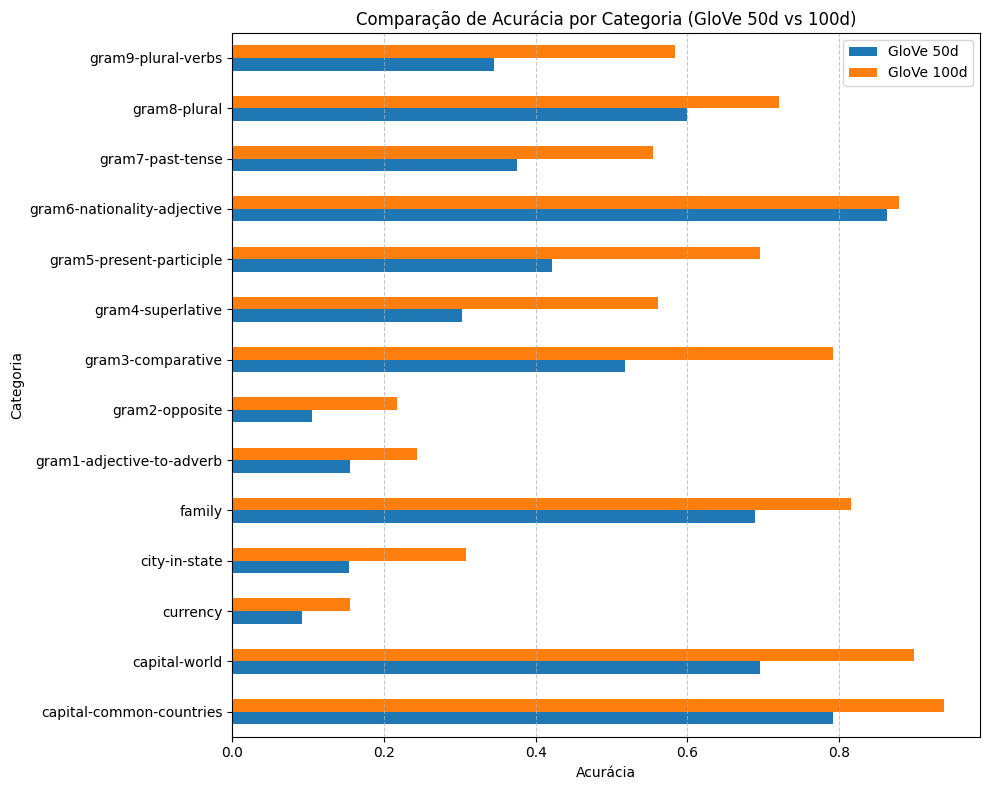

In [ ]:
# gráfico de barras comparando a acurácia por categoria (50d vs 100d)
# Dica: junte df50 e df100 pela coluna "categoria" e use .plot.barh()

df_comparacao = pd.merge(
    df50.rename(columns={'acurácia': 'GloVe 50d'}),
    df100.rename(columns={'acurácia': 'GloVe 100d'}),
    on='categoria'
)

# Configurar a categoria como índice e plotar usando .plot.barh()
df_comparacao.set_index('categoria')[['GloVe 50d', 'GloVe 100d']].plot.barh(figsize=(10, 8))
plt.title('Comparação de Acurácia por Categoria (GloVe 50d vs 100d)')
plt.xlabel('Acurácia')
plt.ylabel('Categoria')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Pergunta 1.1** Quais categorias de analogia o modelo resolve melhor e quais resolve pior? Levante uma hipótese que explique a diferença (pense em frequência das palavras e em quanto o contexto local revela cada relação).

**✍️ Resposta 1.1:**

O modelo teve melhor desempenho nas analogias de países e capitais e na relação entre nacionalidade e adjetivo. Já as categorias de moeda, cidade e estado e adjetivo para advérbio tiveram resultados piores. Isso pode acontecer porque algumas relações aparecem com mais frequência nos dados de treinamento e são mais fáceis de identificar pelo contexto das palavras.

**Pergunta 1.2** O que aconteceu ao passar de 50 para 100 dimensões? Por que a correlação no SimLex-999 é bem menor que no WordSim-353 para os dois modelos?

**✍️ Resposta 1.2:**

Ao passar de 50 para 100 dimensões, a acurácia aumentou na maioria das categorias, pois vetores maiores conseguem representar mais informações sobre as palavras. A correlação no SimLex-999 é menor porque ele avalia a similaridade real entre os significados, enquanto o WordSim-353 também considera associações entre palavras. Como o GloVe aprende com base nos contextos em que as palavras aparecem, pode identificar associações sem representar tão bem a semelhança de significado.

## Parte 2: Suas próprias analogias (2,0 pontos)

### 2.1 TODO: implemente o avaliador
Complete `avaliar_analogias`, que recebe uma lista de tuplas `(a, b, c, d)` representando *a : b :: c : d* e calcula:
- **acc@1**: fração em que `d` é a **primeira** resposta;
- **acc@5**: fração em que `d` está entre as **5 primeiras**.

O parâmetro `metodo` escolhe entre `"add"` (3CosAdd, `most_similar`) e `"mul"` (3CosMul, `most_similar_cosmul`). Analogias com palavras fora do vocabulário devem ser ignoradas e contadas à parte.

In [ ]:
def avaliar_analogias(wv, analogias, metodo="add", topn=5):
    acertos1, acertos5, avaliadas, oov = 0, 0, 0, 0
    detalhes = []   # lista de dicts com a, b, c, esperado, previsto_top5
    for a, b, c, d in analogias:
        # TODO: pule (e conte em oov) analogias com palavras fora do vocabulário
        if any(p not in wv.key_to_index for p in [a, b, c, d]):
            oov += 1
            continue

        # TODO: chame wv.most_similar ou wv.most_similar_cosmul conforme `metodo`
        if metodo == "add":
            resultados = wv.most_similar(
                positive=[b, c],
                negative=[a],
                topn=topn
            )
        elif metodo == "mul":
            resultados = wv.most_similar_cosmul(
                positive=[b, c],
                negative=[a],
                topn=topn
            )
        else:
            raise ValueError("metodo deve ser 'add' ou 'mul'")

        # TODO: atualize acertos1, acertos5, avaliadas e detalhes
        previstos = [palavra for palavra, _ in resultados]
        previsto_top1 = previstos[0] if previstos else None

        avaliadas += 1

        acertou1 = (previsto_top1 == d)
        acertou5 = (d in previstos[:5])

        if acertou1:
            acertos1 += 1
        if acertou5:
            acertos5 += 1

        detalhes.append({
            "a": a,
            "b": b,
            "c": c,
            "esperado": d,
            "previsto_top1": previsto_top1,
            "previsto_top5": previstos,
            "acertou@1": acertou1,
            "acertou@5": acertou5
        })

    return {"acc@1": acertos1 / max(avaliadas, 1),
            "acc@5": acertos5 / max(avaliadas, 1),
            "avaliadas": avaliadas, "oov": oov}, pd.DataFrame(detalhes)

### 2.2 TODO: crie seu conjunto de analogias
Crie **pelo menos 12 analogias**, com no mínimo 4 em cada uma de **3 categorias diferentes** de sua escolha. Evite as categorias que já existem no Google Analogy (capitais, moedas, plural...). Sugestões: animal → filhote, instrumento → músico, país → idioma, empresa → produto, ferramenta → ação, esporte → equipamento, cor → objeto típico.

Lembre-se: o vocabulário do GloVe está **em inglês e em minúsculas**.

In [ ]:
minhas_analogias = {
    "animal_filhote": [
        ("dog", "puppy", "cat", "kitten"),
        ("cow", "calf", "horse", "foal"),
        ("sheep", "lamb", "goat", "kid"),
        ("duck", "duckling", "chicken", "chick"),
    ],

    "pais_idioma": [
        ("brazil", "portuguese", "france", "french"),
        ("germany", "german", "italy", "italian"),
        ("japan", "japanese", "china", "chinese"),
        ("russia", "russian", "spain", "spanish"),
    ],

    "instrumento_musico": [
        ("guitar", "guitarist", "piano", "pianist"),
        ("violin", "violinist", "drums", "drummer"),
        ("flute", "flutist", "trumpet", "trumpeter"),
        ("saxophone", "saxophonist", "cello", "cellist"),
    ],
}

In [ ]:
# Avalia cada categoria com os dois métodos (pronto, apenas execute)
linhas, todos_detalhes = [], []
for cat, lista in minhas_analogias.items():
    for metodo in ["add", "mul"]:
        res, det = avaliar_analogias(wv, lista, metodo=metodo)
        linhas.append({"categoria": cat, "método": "3CosAdd" if metodo == "add" else "3CosMul", **res})
        if metodo == "add":
            todos_detalhes.append(det.assign(categoria=cat))

display(pd.DataFrame(linhas).round(2))
detalhes = pd.concat(todos_detalhes, ignore_index=True)
detalhes[~detalhes["acertou@1"]]   # apenas os erros (3CosAdd)

,categoria,método,acc@1,acc@5,avaliadas,oov
0,animal_filhote,3CosAdd,0.00,0.25,4,0
1,animal_filhote,3CosMul,0.25,0.25,4,0
2,pais_idioma,3CosAdd,1.00,1.00,4,0
3,pais_idioma,3CosMul,1.00,1.00,4,0
4,instrumento_musico,3CosAdd,0.50,0.75,4,0
5,instrumento_musico,3CosMul,0.25,0.75,4,0


,a,b,c,esperado,previsto_top1,previsto_top5,acertou@1,acertou@5,categoria
0,dog,puppy,cat,kitten,puppies,"[puppies, kitten, kittens, monkey, rabbit]",False,True,animal_filhote
1,cow,calf,horse,foal,ankle,"[ankle, leg, knee, trainer, roping]",False,False,animal_filhote
2,sheep,lamb,goat,kid,roast,"[roast, roasted, sauce, chicken, fried]",False,False,animal_filhote
3,duck,duckling,chicken,chick,applesauce,"[applesauce, ricotta, boned, chunky, yolks]",False,False,animal_filhote
10,flute,flutist,trumpet,trumpeter,clarinetist,"[clarinetist, flautist, trombonist, harpist, o...",False,False,instrumento_musico
11,saxophone,saxophonist,cello,cellist,pianist,"[pianist, violinist, cellist, composer, flautist]",False,True,instrumento_musico


**Pergunta 2.1** Compare as categorias e os dois métodos. Em seguida, escolha **dois erros** da tabela acima e explique cada um: a resposta do modelo é absurda ou "quase certa"? Ela revela algo sobre os dados de treino ou sobre a própria relação?

**✍️ Resposta 2.1:**

A categoria país -> idioma teve o melhor resultado, com 100% de acertos nos dois métodos. Em instrumento -> músico, o 3CosAdd foi melhor na primeira resposta, enquanto os dois métodos tiveram resultados iguais considerando as cinco primeiras. Já em animal -> filhote, o desempenho foi baixo nos dois casos.

A diferença entre os métodos está na forma como calculam as analogias. O 3CosAdd soma e subtrai os vetores das palavras para encontrar uma relação semelhante. O 3CosMul combina as similaridades entre os vetores usando uma fórmula multiplicativa. Neste teste, nenhum dos dois foi melhor em todas as categorias.

No caso de dog + puppy + cat = kitten, o modelo respondeu puppies, mas colocou kitten entre as cinco primeiras opções. A resposta não foi totalmente errada, pois a palavra tem relação com filhotes, mas não era a esperada.

Já em flute + flutist + trumpet = trumpeter, o modelo respondeu clarinetist. Apesar de também ser um músico, a palavra não corresponde ao instrumento da analogia. Isso mostra que o modelo consegue identificar relações gerais entre palavras, mas nem sempre encontra a correspondência exata.

## Parte 3: `doesnt_match` e polissemia (1,5 pontos)

### 3.1 TODO: grupos com intruso
Crie **6 grupos** de 4 a 6 palavras, cada um com um intruso:
- 3 grupos **fáceis** (o intruso é de outro domínio, ex.: frutas + um teclado);
- 3 grupos **difíceis** (o intruso é do mesmo domínio, mas difere em algum traço, ex.: animais domésticos + um selvagem, ou cores + uma que também é fruta).

In [ ]:
grupos = [
    # 3 grupos fáceis (intruso de outro domínio)
    (["apple", "banana", "orange", "keyboard"], "keyboard", "fácil"),
    (["car", "truck", "bus", "pizza"], "pizza", "fácil"),
    (["dog", "cat", "rabbit", "microscope"], "microscope", "fácil"),
    # 3 grupos difíceis (intruso do mesmo domínio com diferença sutil)
    (["lion", "tiger", "leopard", "cow"], "cow", "difícil"),
    (["red", "blue", "green", "orange"], "orange", "difícil"),
    (["violin", "guitar", "harp", "drums"], "drums", "difícil")
]

for palavras, esperado, nivel in grupos:
    previsto = wv.doesnt_match(palavras)
    marca = "✅" if previsto == esperado else "❌"
    print(f"{marca} [{nivel:7s}] {palavras} → previsto: {previsto} | esperado: {esperado}")

✅ [fácil  ] ['apple', 'banana', 'orange', 'keyboard'] → previsto: keyboard | esperado: keyboard
✅ [fácil  ] ['car', 'truck', 'bus', 'pizza'] → previsto: pizza | esperado: pizza
✅ [fácil  ] ['dog', 'cat', 'rabbit', 'microscope'] → previsto: microscope | esperado: microscope
✅ [difícil] ['lion', 'tiger', 'leopard', 'cow'] → previsto: cow | esperado: cow
✅ [difícil] ['red', 'blue', 'green', 'orange'] → previsto: orange | esperado: orange
❌ [difícil] ['violin', 'guitar', 'harp', 'drums'] → previsto: harp | esperado: drums


### 3.2 TODO: separando sentidos com aritmética vetorial
Embeddings estáticos atribuem **um único vetor** a cada palavra, que mistura todos os seus sentidos. Para cada palavra ambígua da lista:
1. mostre os 8 vizinhos mais próximos;
2. **subtraia** uma palavra associada a um dos sentidos e veja os vizinhos que sobram. Exemplo: `wv.most_similar(positive=["bank"], negative=["money"])`.

Complete o dicionário com mais **três** palavras ambíguas à sua escolha.

In [ ]:
ambiguas = {
    # palavra: (palavra de um sentido, palavra do outro sentido)
    "bank":  ("money", "river"),
    "apple": ("iphone", "fruit"),
    # 3 novas palavras ambíguas:
    "mouse": ("computer", "animal"),
    "crane": ("machine", "bird"),
    "python": ("programming", "snake"),
}

for palavra, (s1, s2) in ambiguas.items():
    print(f"\n=== {palavra} ===")
    print("vizinhos:       ", [w for w, _ in wv.most_similar(palavra, topn=8)])
    print(f"menos '{s1}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s1], topn=8)])
    print(f"menos '{s2}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s2], topn=8)])


=== bank ===
vizinhos:        ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds']
menos 'money': ['toronto-dominion', 'nedcor', 'aozora', 'umum', 'shinsei', 'fukutoku', 'handlowy', 'danske']
menos 'river': ['hsbc', 'ubs', 'commerzbank', 'dresdner', 'citibank', 'nomura', 'banking', 'ufj']

=== apple ===
vizinhos:        ['microsoft', 'ibm', 'intel', 'software', 'dell', 'pc', 'macintosh', 'iphone']
menos 'iphone': ['berry', 'curry', 'grove', 'pecan', 'cherry', 'peach', 'groves', 'pine']
menos 'fruit': ['microsoft', 'aol', 'google', 'realnetworks', 'intel', 'sony', 'yahoo', 'ibm']

=== mouse ===
vizinhos:        ['cat', 'rabbit', 'monkey', 'mice', 'rat', 'spider', 'bugs', 'dog']
menos 'computer': ['karakul', 'raccoon', 'rabbits', 'varden', 'titi', 'sphynx', 'peromyscus', 'microcebus']
menos 'animal': ['joystick', 'cursor', 'gamepad', 'reepicheep', 'keyboard', 'ps/2', 'speakerphone', 'trackball']

=== crane ===
vizinhos:        ['cranes', 'gantry', 

**Pergunta 3.1** Os grupos difíceis enganaram o modelo? Analise um acerto e um erro com base no mecanismo do `doesnt_match`, que calcula a média dos vetores e retorna a palavra mais distante dela.


**✍️ Resposta 3.1:**

Sim, um dos grupos difíceis conseguiu enganar o modelo. No grupo `['violin', 'guitar', 'harp', 'drums']`, o esperado era `drums` (por ser o único de percussão, enquanto os outros são de cordas), mas o modelo identificou `harp` como intruso. Isso acontece porque violino, guitarra e bateria aparecem com frequência muito maior em contextos comuns de bandas de rock/pop moderno, enquanto "harp" (harpa) fica isolada contextualmente. Já no acerto de `['lion', 'tiger', 'leopard', 'cow']`, o modelo identificou corretamente `cow`, pois a média vetorial dos três felinos selvagens se distanciou fortemente do vetor de um animal domesticado e herbívoro.

**Pergunta 3.2** A subtração vetorial conseguiu "isolar" sentidos? Qual sentido é dominante em cada palavra e por quê? Que tipo de modelo resolveria esse problema de forma mais fundamentada?

**✍️ Resposta 3.2:**

Sim, a subtração vetorial foi bastante eficaz para isolar os sentidos. Para "apple", o sentido tecnológico/corporativo é dominante (os vizinhos originais são Microsoft, IBM, Intel), mas ao subtrair "iphone", restaram apenas frutas e árvores frutíferas ("berry", "cherry", "peach"). Em "python", o sentido dominante no corpus é a comédia britânica Monty Python (vizinhos "monty", "cleese"), mas ao subtrair "programming" isolamos serpentes/animais, e ao subtrair "snake" isolamos linguagens de programação ("c++", "javascript").

Esse comportamento ocorre porque os embeddings estáticos acumulam todas as ocorrências de coocorrência em um único ponto geométrico. Para resolver esse problema de forma mais fundamentada, seriam necessários **modelos de linguagem contextualizados** (como BERT, ELMo ou GPT), que geram vetores dinâmicos para a mesma palavra dependendo de sua posição e contexto específico na frase.

## Parte 4: Visualização em espaços reduzidos (2,0 pontos)

### 4.1 TODO: escolha suas categorias
Defina **5 categorias** com **8 palavras** cada. Ao menos **uma** delas deve ser "difícil" de separar de outra (ex.: *frutas* e *cores*, *esportes* e *países*, *emoções positivas* e *emoções negativas*).

In [ ]:
categorias = {
    "positive_emotions": ["joy", "happy", "love", "peace", "hope", "pride", "relief", "delight"],
    "negative_emotions": ["sad", "anger", "fear", "grief", "guilt", "shame", "envy", "hate"],
    "fruits": ["apple", "banana", "grape", "peach", "lemon", "cherry", "orange", "melon"],
    "furniture": ["chair", "table", "desk", "bed", "sofa", "cabinet", "shelf", "drawer"],
    "countries": ["brazil", "canada", "france", "germany", "japan", "india", "italy", "spain"]
}

palavras, rotulos = [], []
for cat, lista in categorias.items():
    for p in lista:
        if p in wv:
            palavras.append(p); rotulos.append(cat)
        else:
            print("fora do vocabulário:", p)
X = np.array([wv[p] for p in palavras])
cores = dict(zip(categorias, plt.cm.tab10.colors))
print(X.shape)

(40, 100)


In [ ]:
def plotar_2d(coords, titulo, ax=None):
    ax = ax or plt.figure(figsize=(9, 7)).gca()
    for cat in categorias:
        idx = [i for i, r in enumerate(rotulos) if r == cat]
        ax.scatter(coords[idx, 0], coords[idx, 1], color=cores[cat], label=cat, s=40)
        for i in idx:
            ax.annotate(palavras[i], coords[i], xytext=(3, 2), textcoords="offset points", fontsize=8)
    ax.set_title(titulo); ax.grid(alpha=.3)
    return ax

### 4.2 TODO: PCA e t-SNE lado a lado
Gere uma figura com **4 subplots**: PCA e t-SNE com `perplexity` igual a 5, 15 e 30. Use `random_state=42`. Mostre no título do PCA a **variância explicada** pelos 2 componentes.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


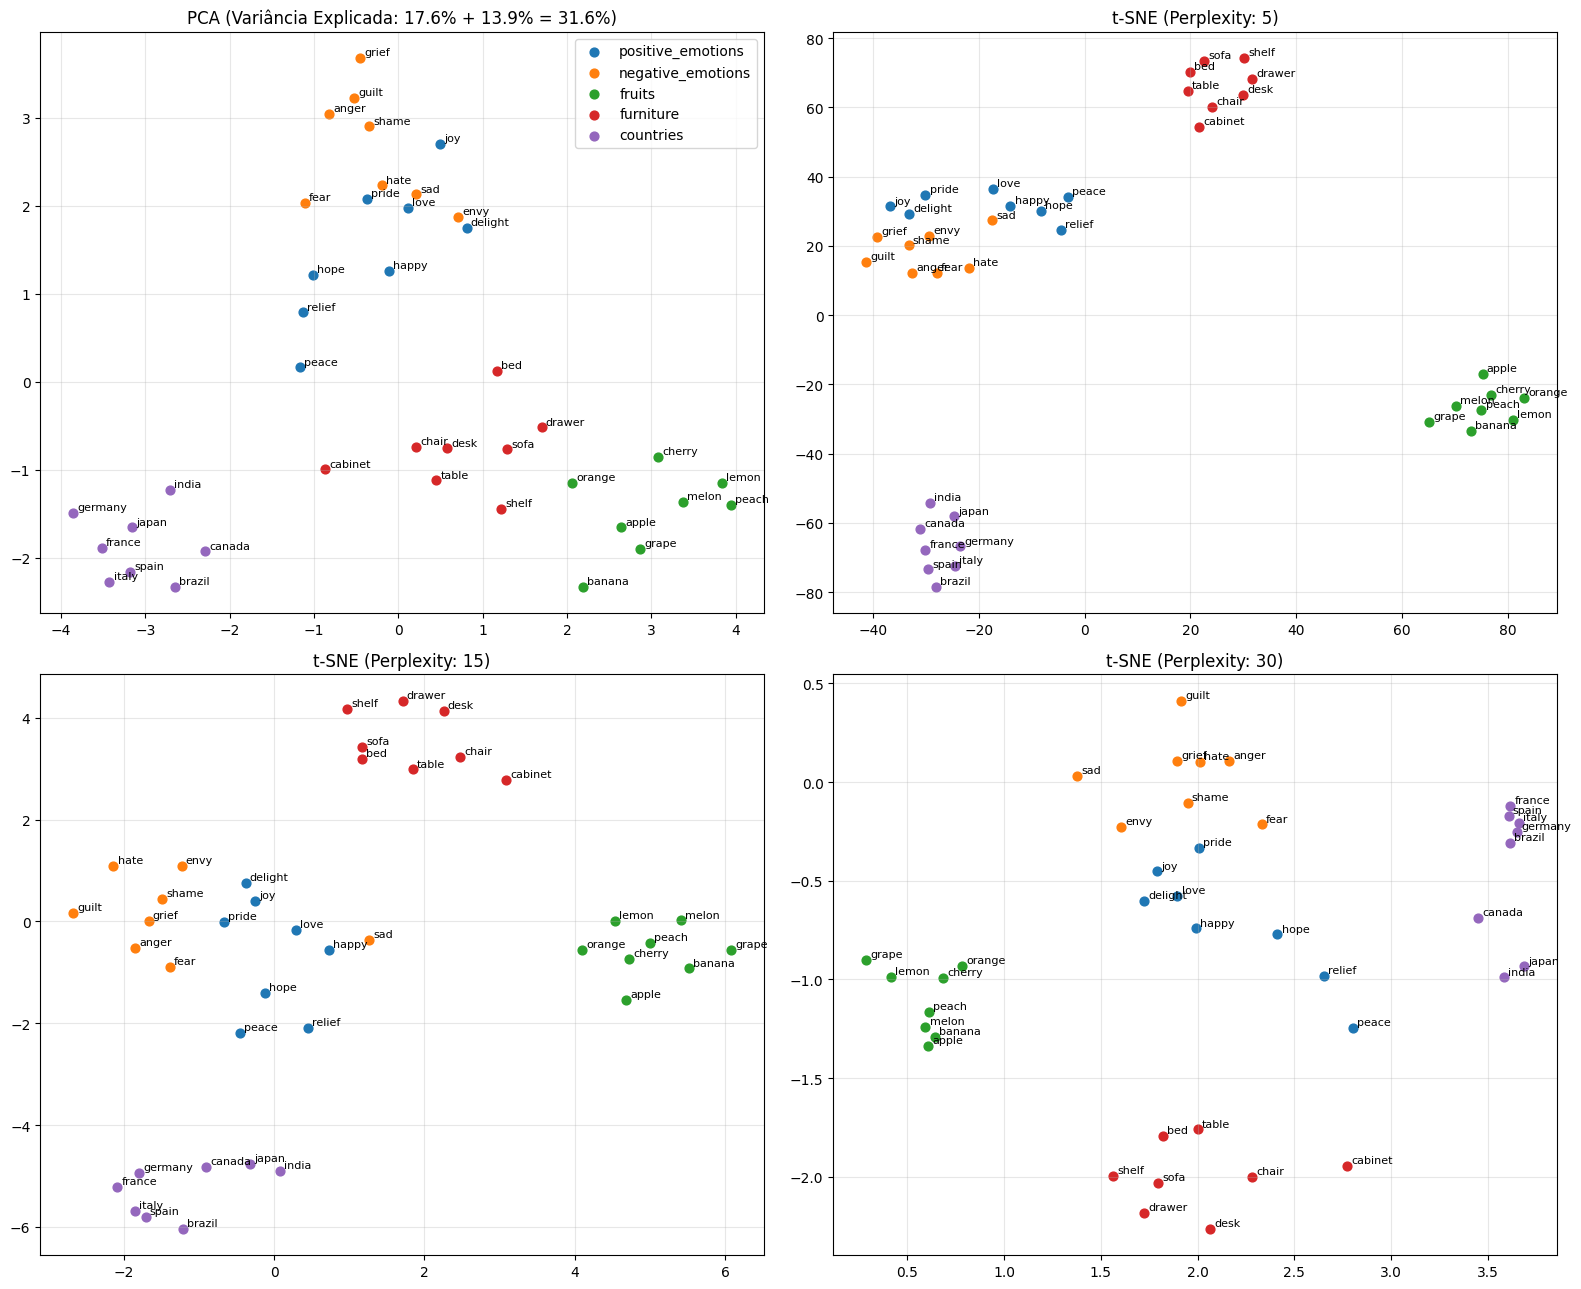

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# PCA em axes[0, 0]
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
var_explicada = pca.explained_variance_ratio_ * 100
titulo_pca = f"PCA (Variância Explicada: {var_explicada[0]:.1f}% + {var_explicada[1]:.1f}% = {var_explicada.sum():.1f}%)"
plotar_2d(X_pca, titulo_pca, ax=axes[0, 0])

# t-SNE com perplexity 5, 15 e 30 nos demais eixos
perplexities = [5, 15, 30]
coords_tsne = []

for i, perp in enumerate(perplexities):
    r, c = (0, 1) if i == 0 else ((1, 0) if i == 1 else (1, 1))

    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, n_iter=1000)
    X_tsne = tsne.fit_transform(X)
    plotar_2d(X_tsne, f"t-SNE (Perplexity: {perp})", ax=axes[r, c])

axes[0, 0].legend()
plt.tight_layout(); plt.show()

### 4.3 TODO: uma relação como direção
Escolha uma **relação** (diferente de gênero e de país → capital, que já aparecem no tutorial) e pelo menos **6 pares** que a exemplifiquem. Use a função `plotar_relacoes` do tutorial, copiada abaixo, para desenhar as setas no plano do PCA.

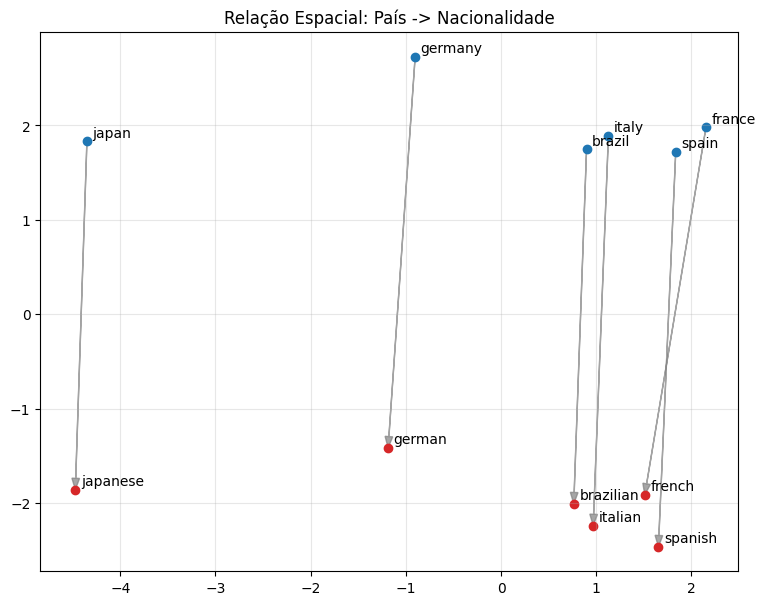

In [ ]:
def plotar_relacoes(pares, titulo):
    ps = [p for par in pares for p in par]
    coords = PCA(n_components=2, random_state=42).fit_transform(np.array([wv[p] for p in ps]))
    plt.figure(figsize=(9, 7))
    for i in range(0, len(ps), 2):
        (x0, y0), (x1, y1) = coords[i], coords[i + 1]
        plt.arrow(x0, y0, x1 - x0, y1 - y0, head_width=0.08, length_includes_head=True, color="gray", alpha=.7)
        plt.scatter([x0], [y0], color="tab:blue"); plt.scatter([x1], [y1], color="tab:red")
        plt.annotate(ps[i], (x0, y0), xytext=(4, 3), textcoords="offset points")
        plt.annotate(ps[i + 1], (x1, y1), xytext=(4, 3), textcoords="offset points")
    plt.title(titulo); plt.grid(alpha=.3); plt.show()

# Definição de 6 pares para a relação País -> Nacionalidade
meus_pares = [
    ("brazil", "brazilian"),
    ("france", "french"),
    ("germany", "german"),
    ("italy", "italian"),
    ("japan", "japanese"),
    ("spain", "spanish")
]

plotar_relacoes(meus_pares, "Relação Espacial: País -> Nacionalidade")

**Pergunta 4.1** Compare PCA e t-SNE: qual separa melhor as suas categorias? O que muda quando a `perplexity` aumenta? Em qual método é legítimo comparar a **distância entre grupos diferentes**? Comente o par de categorias "difícil" que você escolheu.

**✍️ Resposta 4.1:**

O t-SNE, principalmente com perplexidades 15 e 30, separou melhor as categorias em grupos, enquanto no PCA houve algumas sobreposições. Com perplexidade 5, os grupos ficaram mais fragmentados, mas, com valores maiores, ficaram mais organizados.

A distância entre os grupos deve ser interpretada com mais cuidado no t-SNE, pois ele prioriza as relações entre pontos próximos. O PCA, por ser uma projeção linear, permite observar melhor as direções e a variância dos dados, embora também possa perder informações do espaço original.

Um exemplo é o par positive_emotions e negative_emotions: no PCA, as categorias ficaram próximas e com alguma sobreposição, provavelmente por ambas representarem emoções. Já no t-SNE com perplexidade 30, elas apareceram em grupos mais separados, indicando que o modelo consegue distinguir emoções positivas e negativas, apesar da semelhança entre elas.

**Pergunta 4.2** As setas da sua relação ficaram aproximadamente paralelas? Por que esse teste deve ser feito com PCA e não com t-SNE? O que o paralelismo diz sobre o funcionamento das analogias da Parte 2?

**✍️ Resposta 4.2:**

As setas ficaram aproximadamente paralelas, indicando uma direção semelhante entre países e nacionalidades. O PCA é mais adequado para observar esse padrão porque é uma projeção linear, enquanto o t-SNE prioriza a proximidade entre pontos e pode distorcer as relações globais. Esse paralelismo sugere que o modelo representa essa relação semântica por direções semelhantes no espaço vetorial, o que ajuda a explicar como as operações vetoriais permitem resolver analogias.


## Parte 5: Medindo viés de gênero (1,5 pontos)

Bolukbasi et al. (2016) mostraram que é possível identificar uma **direção de gênero** no espaço vetorial e medir o quanto palavras supostamente neutras, como profissões, se inclinam para um dos lados.

### 5.1 TODO: construa o eixo de gênero
1. Calcule o eixo como a **média** das diferenças normalizadas `wv[m] - wv[f]` para os pares definidos abaixo e normalize o resultado (norma 1).
2. Para cada profissão, calcule a **similaridade de cosseno** com o eixo. Valores positivos significam inclinação ao masculino; negativos, ao feminino.
3. Faça um gráfico de barras horizontais ordenado pelo valor.

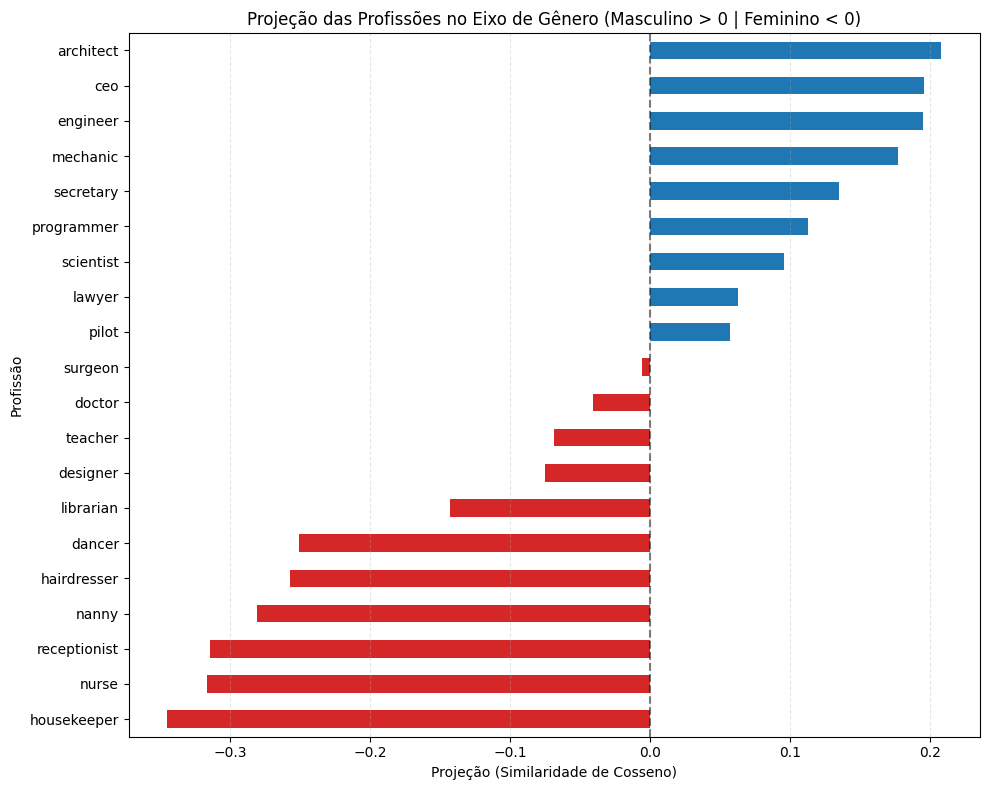

In [ ]:
pares_genero = [("he", "she"), ("man", "woman"), ("his", "her"),
                ("male", "female"), ("boy", "girl"), ("father", "mother")]

profissoes = ["doctor", "nurse", "engineer", "teacher", "programmer", "secretary",
              "scientist", "receptionist", "pilot", "librarian", "ceo", "housekeeper",
              "surgeon", "dancer", "mechanic", "hairdresser", "architect", "nanny",
              "lawyer", "designer"]

def normalizar(v):
    return v / np.linalg.norm(v)

# Eixo de gênero
diferencas = [normalizar(wv[m]) - normalizar(wv[f]) for m, f in pares_genero]
eixo = normalizar(np.mean(diferencas, axis=0))

# Projeções (similaridade de cosseno entre wv[p] da profissão e o eixo)
projecoes = pd.Series({
    p: np.dot(normalizar(wv[p]), eixo) for p in profissoes
}).sort_values()

# Gráfico de barras horizontais com cores separadas para masculino (positivo) e feminino (negativo)
plt.figure(figsize=(10, 8))
cores_barras = ["tab:red" if val < 0 else "tab:blue" for val in projecoes.values]
projecoes.plot(kind="barh", color=cores_barras)

plt.axvline(0, color="black", linestyle="--", alpha=0.5)
plt.title("Projeção das Profissões no Eixo de Gênero (Masculino > 0 | Feminino < 0)")
plt.xlabel("Projeção (Similaridade de Cosseno)")
plt.ylabel("Profissão")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 4 palavras com gênero explícito
palavras_genero = ["king", "queen", "actor", "actress"]
# 4 palavras neutras
palavras_neutras = ["table", "water", "computer", "tree"]

print("=== Projeções de Sanidade (Eixo de Gênero) ===")
for p in palavras_genero:
    proj = np.dot(normalizar(wv[p]), eixo)
    print(f"[Explícita] {p:10s} -> Projeção: {proj:+.4f}")

print()
for p in palavras_neutras:
    proj = np.dot(normalizar(wv[p]), eixo)
    print(f"[Neutras]   {p:10s} -> Projeção: {proj:+.4f}")

=== Projeções de Sanidade (Eixo de Gênero) ===
[Explícita] king       -> Projeção: +0.2773
[Explícita] queen      -> Projeção: -0.1793
[Explícita] actor      -> Projeção: +0.0014
[Explícita] actress    -> Projeção: -0.4095

[Neutras]   table      -> Projeção: +0.0459
[Neutras]   water      -> Projeção: -0.0635
[Neutras]   computer   -> Projeção: +0.1144
[Neutras]   tree       -> Projeção: +0.0071


**Pergunta 5.1** Quais profissões são mais "masculinas" e mais "femininas" no espaço? As palavras de controle se comportaram como esperado? De onde vem esse viés e cite **um** cenário concreto em que ele poderia causar dano em um sistema real que usa esses embeddings.

**✍️ Resposta 5.1:**

As profissões mais associadas ao masculino foram architect, ceo e engineer. Já housekeeper, nurse e receptionist ficaram mais associadas ao feminino. As palavras de controle apresentaram os resultados esperados: king e actor tiveram valores positivos, enquanto queen e actress tiveram valores negativos. Já table, water e tree ficaram próximos de zero.

Esse viés vem dos dados de treinamento, que refletem estereótipos sociais presentes nos textos. Um exemplo de dano seria um sistema de seleção de currículos que desfavorecesse candidatas a vagas de engenharia por associar termos ligados ao feminino a profissões consideradas masculinas.

## Parte 6: Reflexão final (1,0 ponto)

**Pergunta 6.1** Em até 8 linhas: você usaria esses embeddings estáticos como representação de entrada em uma aplicação real hoje? Para que tipo de tarefa ainda faz sentido, e em que casos você preferiria embeddings contextuais? Use pelo menos dois resultados deste laboratório como argumento.

**✍️ Resposta 6.1:**

Eu evitaria usar embeddings estáticos em aplicações que exigem alta precisão, pois eles representam cada palavra com um único vetor, sem considerar o contexto, misturando sentidos diferentes de palavras como bank e apple. Além disso, podem reproduzir preconceitos presentes nos dados de treinamento, como o viés de gênero observado nas profissões. Ainda são úteis em tarefas simples, como buscas por palavras-chave e aplicações com poucos recursos computacionais. Para tarefas mais complexas, como tradução, análise de sentimentos e assistentes conversacionais, eu preferiria modelos como BERT e LLMs, que consideram o contexto da frase.


### Declaração de uso de IA
Marque e descreva brevemente:
- [ ] Não usei ferramentas de IA.
- [x] Usei IA para gerar ou corrigir código nas partes: Parte 1 (comparação GloVe), Parte 2 (função de avaliação), Parte 4 (PCA/t-SNE subplots e gráfico de relações) e Parte 5 (eixo de gênero e sanidade).
- [x] Usei IA para revisar o texto das respostas.

**Ferramenta(s) usada(s) e como:** Usei o assistente de IA integrado (Colab Composer) para gerar e debugar os trechos de visualização e cálculo do eixo de gênero, além de refinar a redação explicativa das respostas teóricas com base nos resultados obtidos nos experimentos.

> Respostas escritas copiadas de IA sem relação com os **seus** resultados não recebem nota.

## Bônus: treinando e comparando Word2Vec (+1,0 ponto)

Treine **dois** modelos Word2Vec no corpus *text8* (≈17 milhões de tokens da Wikipédia em inglês) que difiram em **um único** hiperparâmetro. Sugestões: `sg=0` (CBOW) vs. `sg=1` (Skip-gram), ou `window=2` vs. `window=10`. Avalie os dois com as mesmas métricas da Parte 1 (use `restrict_vocab=30_000` nas analogias) e compare os vizinhos de 3 palavras à sua escolha.

⏱️ Cada treino leva aproximadamente 2 a 6 minutos no Colab, com `epochs=5` e `workers=4`.

In [ ]:
import sys
import smart_open
# Força a compatibilidade com a sintaxe de importação antiga do gensim-data
smart_open.smart_open = smart_open.open
sys.modules['smart_open.smart_open'] = smart_open

FAZER_BONUS = True

if FAZER_BONUS:
    import gensim.downloader as api
    from gensim.models import Word2Vec
    from gensim.test.utils import datapath
    import pandas as pd
    import time

    # 1. Carrega o corpus text8
    print("Baixando o corpus text8...")
    t0 = time.time()
    text8 = api.load("text8")
    corpus = list(text8)
    print(f"Corpus carregado com sucesso! Tempo: {time.time() - t0:.2f}s")

    # 2. Treina o Modelo A (CBOW: sg=0)
    print("\n--- [1/2] Iniciando Treinamento do Modelo A (CBOW, sg=0) ---")
    t_start = time.time()
    modelo_a = Word2Vec(
        sentences=corpus,
        vector_size=50,
        window=5,
        min_count=5,
        sg=0,
        workers=4,
        epochs=3
    )
    print(f"Modelo A treinado com sucesso em {time.time() - t_start:.2f}s!")

    # 3. Treina o Modelo B (Skip-gram: sg=1)
    print("\n--- [2/2] Iniciando Treinamento do Modelo B (Skip-gram, sg=1) ---")
    t_start = time.time()
    modelo_b = Word2Vec(
        sentences=corpus,
        vector_size=50,
        window=5,
        min_count=5,
        sg=1,
        workers=4,
        epochs=3
    )
    print(f"Modelo B treinado com sucesso em {time.time() - t_start:.2f}s!")

    # 4. Avaliações nas analogias (restrict_vocab=30000) e pares de palavras
    print("\nCalculando as métricas de avaliação intrínseca...")
    def avaliar_modelo(model, nome_modelo):
        acc_total, _ = model.wv.evaluate_word_analogies(
            datapath("questions-words.txt"), restrict_vocab=30000
        )
        # WordSim-353
        ws_corr = model.wv.evaluate_word_pairs(datapath("wordsim353.tsv"))[1][0]
        # SimLex-999
        sl_corr = model.wv.evaluate_word_pairs(datapath("simlex999.txt"))[1][0]
        return {
            "Modelo": nome_modelo,
            "Analogias (Acc)": acc_total,
            "WordSim-353 (Spearman)": ws_corr,
            "SimLex-999 (Spearman)": sl_corr
        }

    res_a = avaliar_modelo(modelo_a, "Word2Vec CBOW (sg=0)")
    res_b = avaliar_modelo(modelo_b, "Word2Vec Skip-gram (sg=1)")

    print("\nTabela Comparativa de Desempenho:")
    df_bonus = pd.DataFrame([res_a, res_b]).set_index("Modelo")
    display(df_bonus.round(3))

    # 5. Comparação de vizinhos para 3 palavras
    palavras_teste = ["apple", "computer", "king"]
    print("\n=== Comparação de Vizinhos Próximos ===")
    for p in palavras_teste:
        if p in modelo_a.wv and p in modelo_b.wv:
            vizinhos_a = [w for w, _ in modelo_a.wv.most_similar(p, topn=5)]
            vizinhos_b = [w for w, _ in modelo_b.wv.most_similar(p, topn=5)]
            print(f"\nPalavra: '{p}'")
            print(f"  CBOW (sg=0):      {vizinhos_a}")
            print(f"  Skip-gram (sg=1): {vizinhos_b}")

Baixando o corpus text8...
Corpus carregado com sucesso! Tempo: 6.60s

--- [1/2] Iniciando Treinamento do Modelo A (CBOW, sg=0) ---
Modelo A treinado com sucesso em 73.78s!

--- [2/2] Iniciando Treinamento do Modelo B (Skip-gram, sg=1) ---
Modelo B treinado com sucesso em 264.62s!

Calculando as métricas de avaliação intrínseca...

Tabela Comparativa de Desempenho:


,Analogias (Acc),WordSim-353 (Spearman),SimLex-999 (Spearman)
Modelo,,,
Word2Vec CBOW (sg=0),0.198,0.559,0.238
Word2Vec Skip-gram (sg=1),0.255,0.632,0.270



=== Comparação de Vizinhos Próximos ===

Palavra: 'apple'
  CBOW (sg=0):      ['amiga', 'macintosh', 'hypercard', 'intel', 'ibm']
  Skip-gram (sg=1): ['macintosh', 'amiga', 'hypercard', 'pc', 'console']

Palavra: 'computer'
  CBOW (sg=0):      ['digital', 'computing', 'graphics', 'programmer', 'software']
  Skip-gram (sg=1): ['computers', 'hardware', 'microcomputer', 'laptop', 'minicomputer']

Palavra: 'king'
  CBOW (sg=0):      ['prince', 'emperor', 'throne', 'constantine', 'queen']
  Skip-gram (sg=1): ['queen', 'pretender', 'prince', 'vii', 'haakon']


**Pergunta B.1** Qual modelo foi melhor em cada métrica? Relacione o resultado ao hiperparâmetro que você variou. Compare também com o GloVe da Parte 1: por que o GloVe pré-treinado é tão melhor?

**✍️ Resposta B.1:**

O Skip-gram teve resultados melhores que o CBOW em todas as métricas: analogias (0,255 contra 0,198), WordSim-353 (0,632 contra 0,559) e SimLex-999 (0,270 contra 0,238).

Isso pode estar relacionado à forma como cada modelo aprende. O Skip-gram tenta prever as palavras do contexto a partir de uma palavra, enquanto o CBOW usa o contexto para prever a palavra central. Neste experimento, o Skip-gram conseguiu representar melhor as relações entre as palavras.

Comparado ao GloVe pré-treinado, que obteve 0,639 de acurácia em analogias, os dois modelos tiveram resultados inferiores. Uma possível explicação é o tamanho dos dados: o text8 possui cerca de 17 milhões de tokens, enquanto o GloVe foi treinado com mais de 6 bilhões. Essa diferença oferece ao GloVe muito mais exemplos para aprender as relações entre as palavras.


---
### Referências
- Mikolov et al. (2013). *Efficient Estimation of Word Representations in Vector Space.*
- Pennington, Socher & Manning (2014). *GloVe: Global Vectors for Word Representation.*
- Levy & Goldberg (2014). *Linguistic Regularities in Sparse and Explicit Word Representations.*
- Hill, Reichart & Korhonen (2015). *SimLex-999: Evaluating Semantic Models with (Genuine) Similarity Estimation.*
- Bolukbasi et al. (2016). *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings.*
- Gonen & Goldberg (2019). *Lipstick on a Pig: Debiasing Methods Cover up Systematic Gender Biases in Word Embeddings But do not Remove Them.*